# Two-Layer Neural Network on MNIST

This notebook loads the MNIST dataset, builds a Keras two-layer neural network, trains it, evaluates test accuracy, and plots training accuracy.

## 1. Import Dependencies

In [1]:
# Import plotting, numerical computing, and TensorFlow utilities.
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist 

I0000 00:00:1794776341.662824    2282 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794776341.663324    2282 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794776341.833686    2282 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794776344.528656    2282 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

## 2. Load and Preprocess the MNIST Dataset

In [2]:
# Load the MNIST handwritten-digit dataset.
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("Original shapes:")
print("Training data:", x_train.shape, y_train.shape)
print("Testing data:", x_test.shape, y_test.shape)

x_train = x_train.reshape(-1, 28 * 28).astype("float32") / 255.0
x_test = x_test.reshape(-1, 28 * 28).astype("float32") / 255.0

print("Reshaped and normalized shapes:")
print("Training data:", x_train.shape, y_train.shape)
print("Testing data:", x_test.shape, y_test.shape)

Original shapes:
Training data: (60000, 28, 28) (60000,)
Testing data: (10000, 28, 28) (10000,)
Reshaped and normalized shapes:
Training data: (60000, 784) (60000,)
Testing data: (10000, 784) (10000,)


## 3. Define the Two-Layer Neural Network

In [3]:
# Wrap the two dense layers, training, and evaluation in a reusable class.
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size):
        self.model = keras.Sequential([
            layers.Dense(hidden_size, activation='relu', input_shape=(input_size,)),
            layers.Dense(output_size, activation='softmax')
        ])
        self.model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    def train(self, x_train, y_train, epochs=5, batch_size=32):
        self.model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size)

    def evaluate(self, x_test, y_test):
        return self.model.evaluate(x_test, y_test)

## 4. Train and Evaluate the Network

In [4]:
# Create the network and train it for five epochs.
net = TwoLayerNet(input_size=784, hidden_size=128, output_size=10)
net.train(x_train, y_train, epochs=5, batch_size=32)
test_loss, test_accuracy = net.evaluate(x_test, y_test)
print(f"Test loss: {test_loss}, Test accuracy: {test_accuracy}")

Epoch 1/5


/workspaces/ECE5831/ece-5831-2026-assignments/A_08/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794776468.164707    2282 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 572us/step - accuracy: 0.9247 - loss: 0.2655
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 565us/step - accuracy: 0.9650 - loss: 0.1177
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 540us/step - accuracy: 0.9756 - loss: 0.0797
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 559us/step - accuracy: 0.9823 - loss: 0.0591
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 540us/step - accuracy: 0.9857 - loss: 0.0465
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step - accuracy: 0.9751 - loss: 0.0834
Test loss: 0.08341637253761292, Test accuracy: 0.9750999808311462


## 5. Inspect Training Accuracy

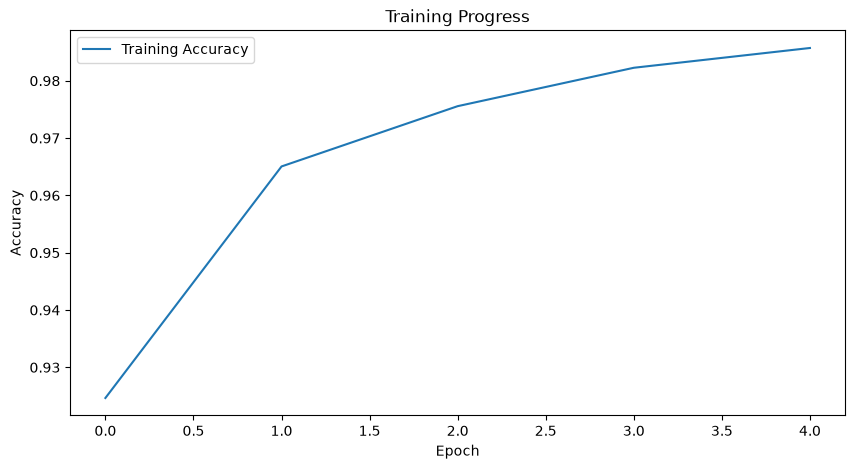

In [9]:
# Plot accuracy recorded during training.
plt.figure(figsize=(10, 5))
plt.plot(net.model.history.history['accuracy'], label='Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training Progress')
plt.legend()
plt.show()